In [ ]:
#@title

%matplotlib inline
#%matplotlib notebook
%reload_ext autoreload
%autoreload 2

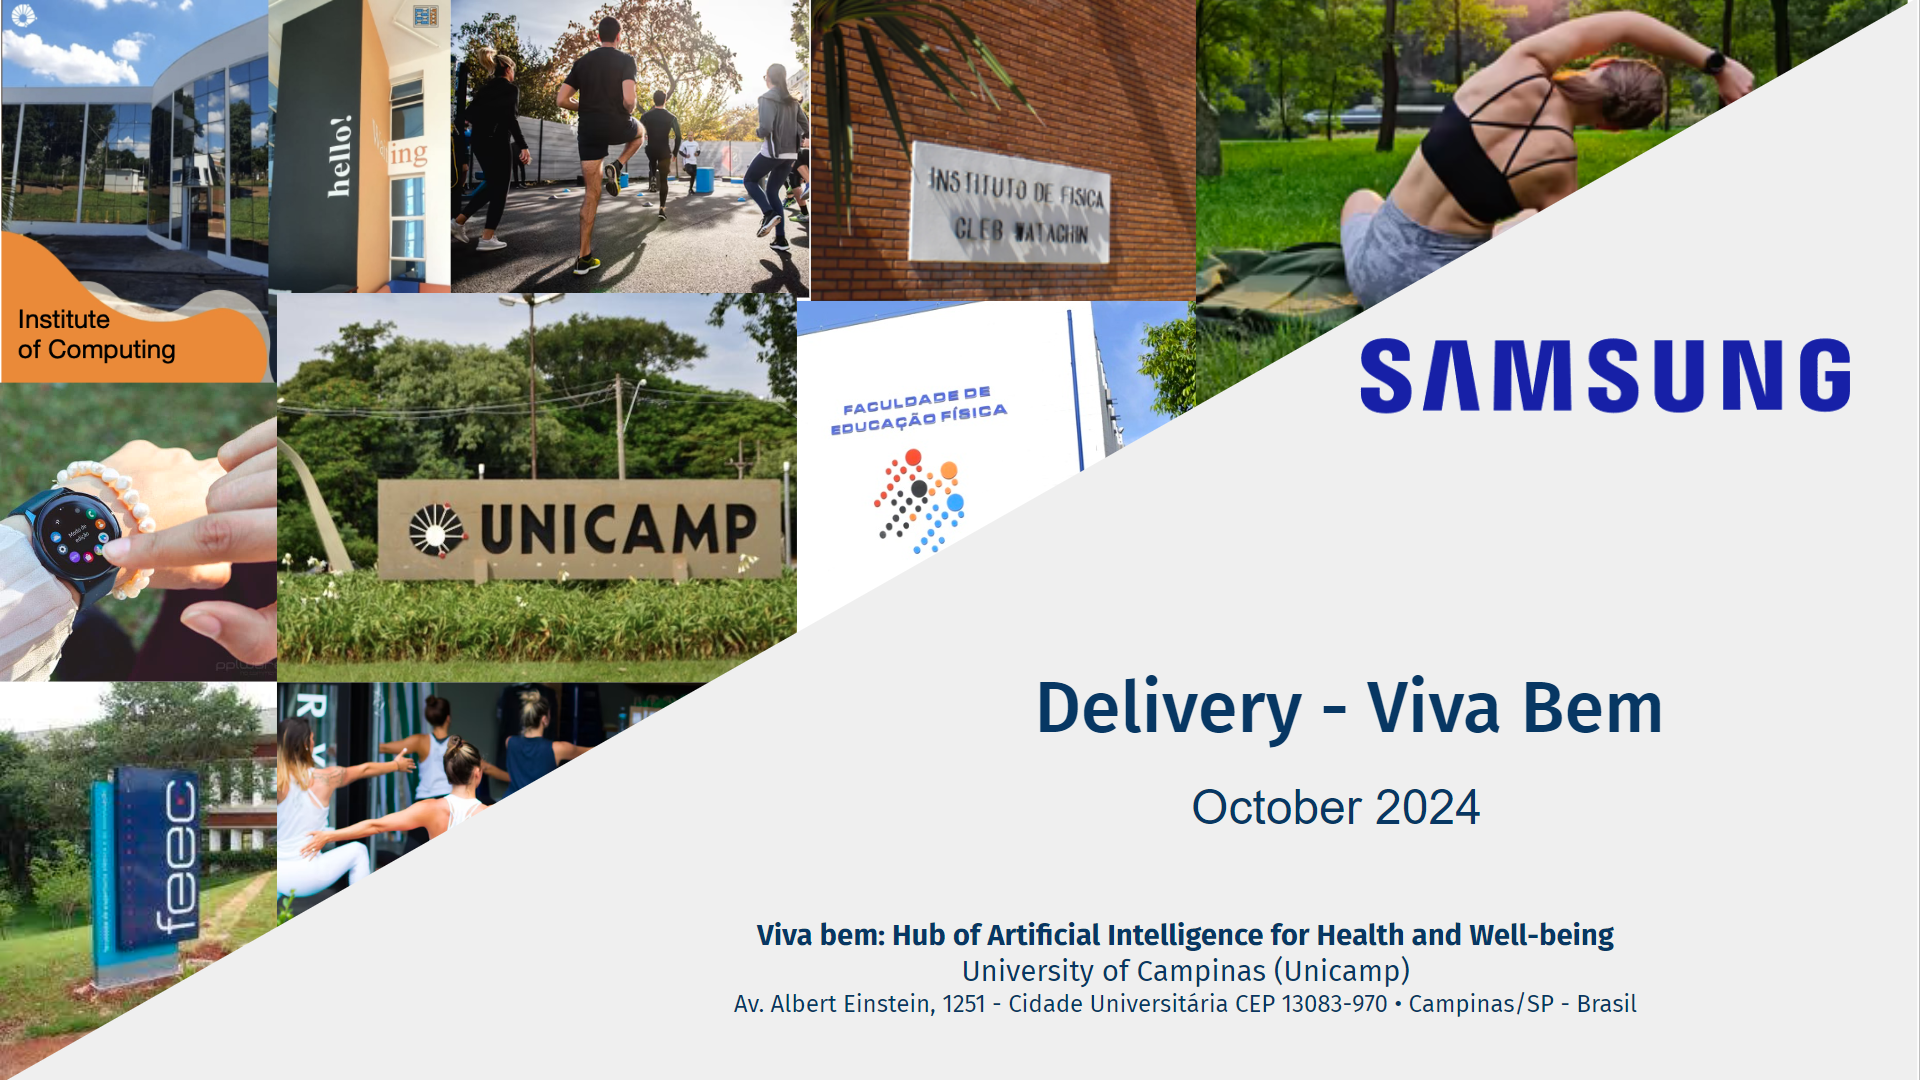

---
---   
    
# <center> A2 - Human Activity Recognition </center>

---
---

## <center> Abstract </center>

Human Activity Recognition (HAR) has emerged as a prominent topic in the field of Machine Learning (ML), particularly in the context of mobile devices. Modern mobile devices are equipped with sensors capable of collecting real-time user data, enabling the detection of individual patterns. The primary goal of HAR is to design and implement models that accurately detect and classify human activities. This capability holds significant potential for applications in healthcare, fitness, smart environments, and beyond, making it a critical area of research and development. This project focuses on designing a model optimized for mobile devices with limited resources while maintaining high performance. To achieve this, we utilized benchmark datasets and various ML techniques. The proposed model is a Light-Weight Convolutional Neural Network (LWCNN) that leverages Recurrence Plots to process sensor data effectively and classify human activities.

---
---   
    
## <center> 1. Lib loading </center>

In [ ]:
import time
from datetime import datetime
import json
import random

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from torchsummary import summary
from torchvision import models

from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import LabelEncoder

In [ ]:

activity_column = 'activity'

NUM_CLIENTS = 36
NUM_CLASSES = 4
WINDOW_SIZE = 128
TRAINING_PERCENTAGE = 0.75
STRIDE = 10
NUM_EPOCHS = 400
PATIENCE = 10
LEARNING_RATE = 1e-4


DEVICE = torch.device("cuda") 

INT_MAX = 2**32-1
random_seed = random.randint(0,INT_MAX)
#np.random.seed(2552391037)
np.random.seed(random_seed)

print(random_seed)

---
---   
    
## <center> 2. Data </center>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#Read folders
path = '/content/drive/Shareddrives/Viva_Bem/entregáveis_software/7th_delivery(January2024)/a2_activity_recognition/data'
folders = os.listdir(path)

## WISDM Dataset

The Wireless Sensor Data Mining (WISDM) dataset is a well-known collection used for Human Activity Recognition (HAR). It contains accelerometer data from mobile devices, collected while users perform various activities such as walking, jogging, sitting, and standing. The dataset includes three accelerometer axes (x, y, z) along with activity labels and timestamps.

The WISDM dataset is widely used to train machine learning models to classify and recognize human activities based on sensor readings. It consists of data from 36 users, each performing multiple activities, providing a rich set of data points for HAR tasks.

## Pre-Processing 

The provided dataset was pre-processed using the following steps. The original dataset can be downloaded at this [link](https://www.cis.fordham.edu/wisdm/dataset.php).

1. **Reading the Data:**  
   The dataset is loaded into a pandas DataFrame from a `.txt` file, with the appropriate delimiter and without headers. Any malformed lines are skipped during this process.

2. **Column Naming:**  
   Since the dataset lacks headers, explicit column names are assigned for clarity: `user_id`, `activity`, `timestamp`, `x`, `y`, and `z`.

3. **Cleaning the 'z' Column:**  
   The 'z' accelerometer values may contain a trailing semicolon (`;`), which is removed using the `rstrip()` function. The values are then converted to floats for further processing.

4. **Balancing the Dataset:**  
   The dataset may suffer from class imbalance (unequal distribution of activity labels). To address this, the dataset is balanced by resampling the underrepresented classes so that each class has the same number of samples. This ensures fair training for machine learning models.

5. **Sorting the Data:**  
   After balancing, the dataset is sorted by `user_id` and `timestamp`, ensuring that the data is ordered chronologically and grouped by users.

6. **Saving the Processed Data:**  
   Finally, the pre-processed and balanced dataset is saved to a new CSV file for later use.

These pre-processing steps help to clean the data, address class imbalance, and ensure the dataset is ready for the next processing steps.


In [ ]:
# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

wisdm = pd.read_csv('path/WISDM.csv', header=None, sep=',', names=['user', 'activity', 'timestamp', 'x', 'y', 'z'])

# Filter for specific activities
wisdm = wisdm.loc[
    (wisdm['activity'] == 'Walking') | 
    (wisdm['activity'] == 'Jogging') | 
    (wisdm['activity'] == 'Sitting') | 
    (wisdm['activity'] == 'Standing') 
].reset_index(drop=True)

wisdm = wisdm.groupby('user').apply(normalize_group)
wisdm = wisdm.reset_index(drop=True)
wisdm

The `get_train_test_data_non_overlapping` function is designed to divide a dataset into training and testing subsets in a way that ensures no overlap between the users in these subsets. The function randomly selects of the users to be included in the training set based on a specified percentage (`TRAINING_PERCENTAGE`), with the remaining users forming the testing set. After splitting the dataset, it creates fixed-length sequences (`WINDOW_SIZE`) from the data for both subsets, with each sequence associated with a label corresponding to the activity of its last entry.

Sequence generation is performed by iterating over the data for each user and extracting sliding windows of sensor readings (e.g., x, y, z axes) with a configurable step size (`STRIDE`). This ensures a consistent input format for model training and testing. The function outputs four arrays: `X_train` and `y_train` for training data, and `X_test` and `y_test` for testing data. By using user-specific splits and generating non-overlapping sequences, the function facilitates a rigorous evaluation of models on data from unseen users, making it ideal for user-independent machine learning pipelines.


In [ ]:
def get_train_test_data_non_overlapping(wisdm, sequence_length=100, train_percentage=0.8, stride=1):
    # Get the unique users
    users = wisdm['user'].unique()
    
    # Determine the number of users to select based on the percentage
    num_train_users = int(len(users) * train_percentage)
    
    # Randomly select users for training
    train_users = np.random.choice(users, num_train_users, replace=False)
    test_users = [user for user in users if user not in train_users]

    print(f"Train Users: {train_users}")
    print(f"Test Users: {test_users}")
    
    # Split the dataset into training and test sets
    train_data = wisdm[wisdm['user'].isin(train_users)]
    test_data = wisdm[wisdm['user'].isin(test_users)]

    # Function to create sequences for each user separately
    def create_sequences(data):
        X, y = [], []
        for user in data['user'].unique():
            user_data = data[data['user'] == user]
            for i in range(0, len(user_data) - sequence_length + 1, stride):
                sequence = user_data.iloc[i:i + sequence_length]
                X.append(sequence[[x_axis, y_axis, z_axis]].values)
                y.append(sequence['activity'].iloc[-1])  # Use the last value in the sequence as the label
        return np.array(X), np.array(y)

    # Create sequences for training and test data
    X_train, y_train = create_sequences(train_data)
    X_test, y_test = create_sequences(test_data)

    return X_train, y_train, X_test, y_test

In [ ]:
X_train, y_train, X_test, y_test = get_train_test_data_non_overlapping(wisdm, WINDOW_SIZE, TRAINING_PERCENTAGE, STRIDE)
print(len(X_train), len(y_train), len(X_test), len(y_test))

After loading the dataset, the shape will be (`WINDOW_SIZE`, 3). The three because we use the axis x, y and z from the accelerometer.

In [ ]:
X_train[0].shape

The axes are defined as \(x\), \(y\), and \(z\), corresponding to the axes of the accelerometer. The thresholds used to create the recurrence plots are defined arbitrarily. Each threshold will generate a separate channel for the final input, resulting in a shape of \(`WINDOW_SIZE`, `WINDOW_SIZE`, 4).


In [ ]:
x_axis = 'x'
y_axis = 'y'
z_axis = 'z'
THRESHOLD_1 = 1.0000 
THRESHOLD_2 = 0.0187
THRESHOLD_3 = 0.0113
THRESHOLD_4 = 1.0000

In [ ]:
def recurrence_plot_vector(data, eps):
    """
    Computes the recurrence plot for a set of vectors based on a given threshold.

    Parameters:
    data: A List of vectors.
    eps (float): The threshold distance for determining recurrence.

    Returns:
    numpy.ndarray: A binary recurrence matrix of size (N, N), where N is the number of vectors in `data`. 
                   An entry is 1 if the distance between two vectors is less than or equal to `eps`, and 0 otherwise.

    """
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(i, N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = recurrence_matrix[j, i] = distance

    # Apply the threshold
    recurrence_matrix = (recurrence_matrix <= eps).astype(int)
    
    return recurrence_matrix


In [ ]:
def transform_to_vector_sequence(sequence):
    """
    Transform a sequence of three-channel data into a one-channel vector sequence.
    
    Parameters:
    - sequence: np.array, shape (sequence_length, 3), where 3 represents the x, y, z channels.
    
    Returns:
    - vector_sequence: list of np.array, the transformed vector sequence.
    """
    vector_sequence = [np.array([x, y, z]) for x, y, z in sequence]
    return vector_sequence

The `transform_and_calculate_recurrence_plots` function uses the accelerometer axes to create recurrence plots with a shape of (`WINDOW_SIZE`, `WINDOW_SIZE`). For each input in `X_train`, it is transformed into a vector sequence (list) using the `transform_to_vector_sequence` function in the following form:

$$
V = \{v_1, v_2, \dots, v_n\} = \{(x_1, y_1, z_1), (x_2, y_2, z_2), \dots, (x_n, y_n, z_n)\}
$$
where  
$$
V \text{ is a set of vectors, }  
v_i \text{ represents a single vector, and } \\
x_i, y_i, \text{ and } z_i \text{ are the data values from the x, y, and z axes for a single sample in the dataset.}  
$$

After this, each vector sequence is transformed into four different recurrence plots by the `recurrence_plot_vector` function. Each plot is created using a specific fixed threshold chosen arbitrarily. The vectors are first transformed into a distance matrix of size (`WINDOW_SIZE`, `WINDOW_SIZE`) using the following equation:

$$
d(v_i, v_j) = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2 + (z_i - z_j)^2}
$$

Each distance matrix is then converted into four binary recurrence plots using the following function:

$$
R_{ij} =
\begin{cases} 
1 & \text{if } d(v_i, v_j) < \epsilon, \text{ where } \epsilon \text{ is an arbitrarily defined threshold,} \\
0 & \text{otherwise.}
\end{cases}
$$


In [ ]:
def transform_and_calculate_recurrence_plots(X_data):
    recurrence_plots = []
    for sequence in X_data:
        vector_sequence = transform_to_vector_sequence(sequence)

        # Generate recurrence matrices for each threshold
        rec_matrix_1 = recurrence_plot_vector(vector_sequence, THRESHOLD_1)
        rec_matrix_2 = recurrence_plot_vector(vector_sequence, THRESHOLD_2)
        rec_matrix_3 = recurrence_plot_vector(vector_sequence, THRESHOLD_3)
        rec_matrix_4 = recurrence_plot_vector(vector_sequence, THRESHOLD_4)
        multi_channel_rec_matrix = np.stack([rec_matrix_1, rec_matrix_2, rec_matrix_3, rec_matrix_4], axis=-1)
            
        recurrence_plots.append(multi_channel_rec_matrix)

    return recurrence_plots

In [ ]:
X_train_recurrence = transform_and_calculate_recurrence_plots(X_train)
X_test_recurrence = transform_and_calculate_recurrence_plots(X_test)

The final shape of the input is (`WINDOW_SIZE`, `WINDOW_SIZE`, 4). Each one of the four channels was built using one of the defined thresholds.

In [ ]:
X_train_recurrence[0][:,:,0].shape

The last step the data is transformed by encoding activity labels, converting data into PyTorch tensors, and preparing it for batch-based training and evaluation. First, the labels (`y_train` and `y_test`) are encoded into integers using a `LabelEncoder`, and the mapping of labels to names is stored for future reference. The feature data (`X_train_recurrence` and `X_test_recurrence`), represented as recurrence plots, is converted into PyTorch tensors of type `float32`, while the encoded labels are converted to tensors of type `long`. The input tensors are then reshaped from a format of `(batch_size, height, width, channels)` to `(batch_size, channels, height, width)` to match the expected input shape for CNN models. Finally, `TensorDataset` and `DataLoader` are used to bundle the data and create iterable datasets for training and testing, with batch sizes of 32. The training data loader shuffles the dataset for better generalization, while the test data loader preserves the original order.


In [ ]:
# Encode labels to integers
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
labels_names = list(label_encoder.classes_)
y_test = label_encoder.transform(y_test)

# Convert X_train and y_train to tensors
X_train_tensor = torch.tensor(X_train_recurrence, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_recurrence, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Reshape the input tensor to have the shape (batch_size, channels, height, width)
X_train_tensor = X_train_tensor.permute(0, 3, 1, 2)  # Change from (batch_size, 40, 40, 4) to (batch_size, 4, 40, 40)
X_test_tensor = X_test_tensor.permute(0, 3, 1, 2)    # Same for test data

# Create DataLoader for training and testing data
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, drop_last=True)

# <center> 3. Proposed Model </center>

### Overview
The proposed model is an adaptation of the **MobileNetV2** architecture from the PyTorch `torchvision` library, customized to perform classification tasks. The modifications ensure compatibility with the specific dataset and task requirements, such as handling 4-channel input data and predicting the desired number of classes.



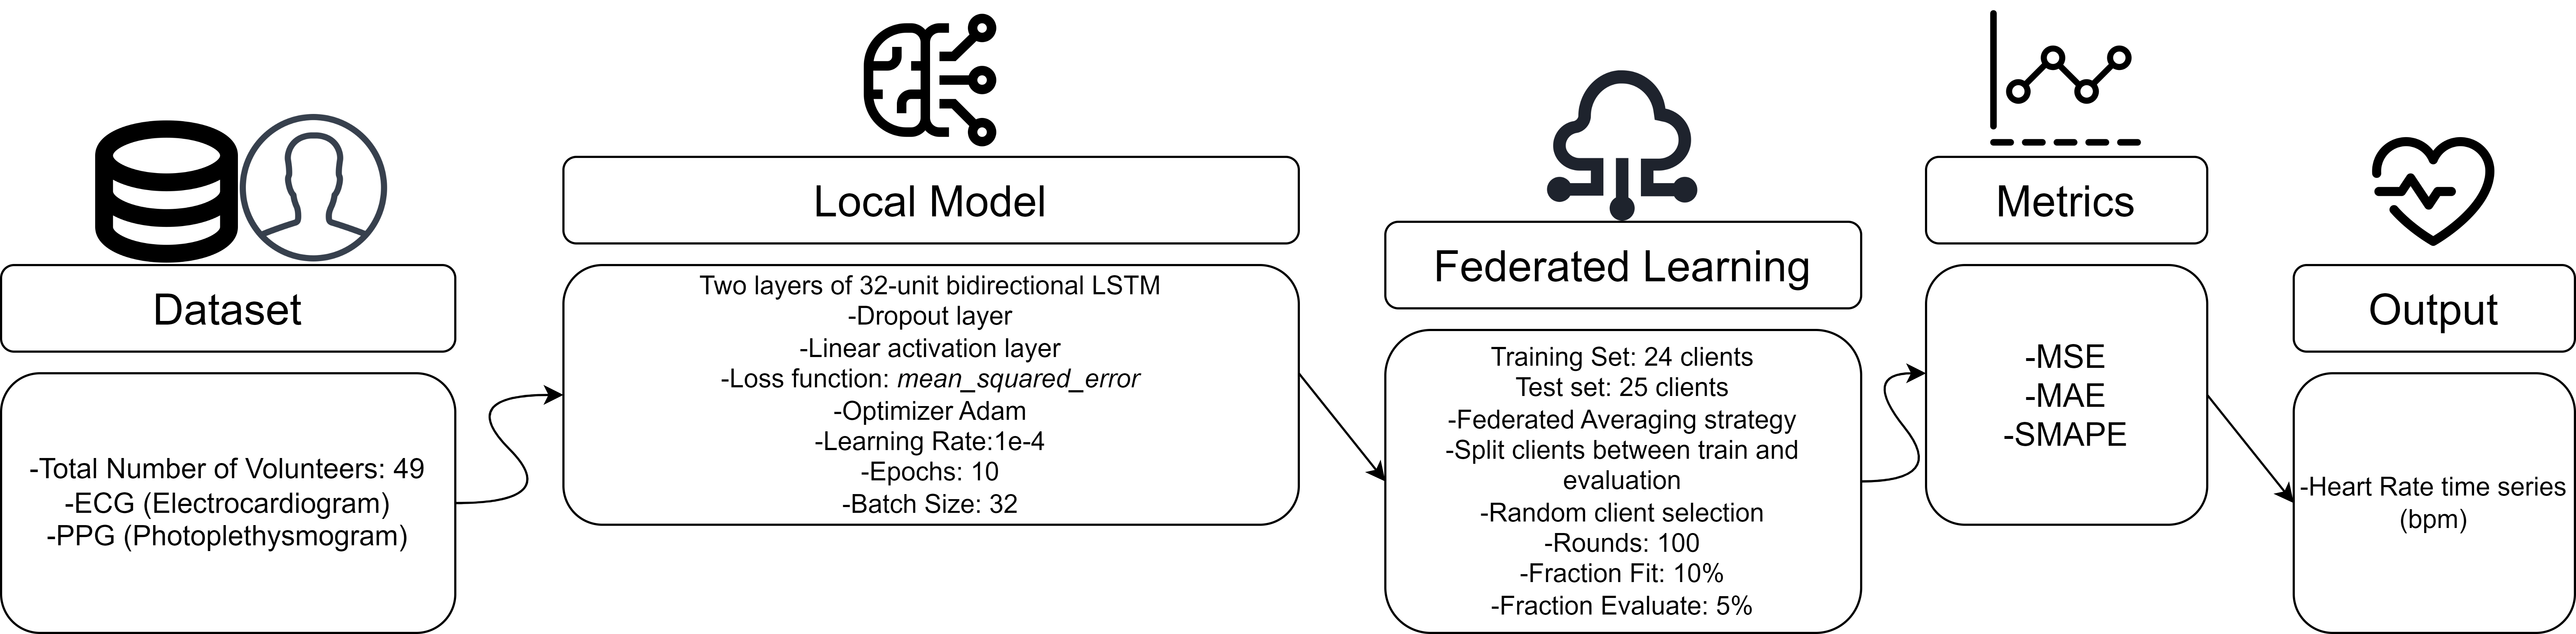


The image depicts a Federated Learning workflow for predicting heart rate time series. Below, we explain each stage:
1. Total Number of Volunteers in the dataset: 49. ECG (Electrocardiogram) and PPG (Photoplethysmogram) signals are used for training and testing models.

2. Local Model:
The local model architecture consists of:
* Two layers of bidirectional LSTMs with 32 units each.
* A Dropout layer to prevent overfitting.
* A Linear activation layer.
* Loss Function: Mean Squared Error (MSE) is used to optimize the model.:
* Optimizer: Adam optimizer is employed with a learning rate of 1e-4.
* Training Configuration: The model is trained for 10 epochs with a batch size of 32.

3. Federated Learning:
* Training Set: 24 clients.
* Test Set: 25 clients.
* Federated Averaging Strategy: The strategy used for aggregating local models from different clients.
* Client Splitting: Clients are split between training and evaluation sets.
* Client Selection: Random client selection is used in each round of federated learning.
* Training Rounds: The model is trained over 100 rounds.
* Fraction Fit: Only 10% of the clients are used to fit the model during each round.
* Fraction Evaluate: 5% of the clients are used for evaluation in each round.

4. Metrics:
The metrics used to evaluate the model are:
* MSE (Mean Squared Error).
* MAE (Mean Absolute Error).
* SMAPE (Symmetric Mean Absolute Percentage Error).

5. Output:
The final output of the system is a Heart Rate time series (measured in beats per minute, bpm).

The next part of code defines two functions for calculating evaluation metrics (MAE and SMAPE) and builds a Bidirectional LSTM model with dropout layers and dense layers for regression tasks, which is compiled using the Adam optimizer and multiple performance metrics, including MAE, MSE, MAPE, precision, and recall.




### Architecture Details
The **ModifiedMobileNetV2** class builds upon the pretrained MobileNetV2 model with the following key adjustments:

1. **Input Layer Modification**:
   - The default MobileNetV2 expects 3-channel input images (RGB). 
   - This implementation modifies the input layer (`Conv2d`) to handle 4-channel input data, matching the recurrence plot data used in this task.

2. **Custom Classification Layer**:
   - The final classification layer is replaced with a fully connected (`Linear`) layer. 
   - This layer's output size is set to match the number of target classes (`NUM_CLASSES`), allowing the model to adapt to the classification task.

3. **Pretrained Weights**:
   - The model initializes using pretrained MobileNetV2 weights to leverage transfer learning. 
   - These weights are loaded from an external file (`mobilenet_v2-b0353104.pth`) to improve model performance and speed up training.

### Forward Method
The `forward` method passes input tensors through the modified MobileNetV2 architecture, producing predictions based on the adapted classifier.

### Key Advantages
- **Efficiency**: MobileNetV2 is a lightweight and efficient architecture, ideal for tasks with resource constraints.
- **Adaptability**: Modifying the input and output layers ensures compatibility with non-standard datasets.
- **Transfer Learning**: Pretrained weights provide a strong initialization, reducing the training time and improving accuracy.

This proposed model is well-suited for the classification task, leveraging the robustness of MobileNetV2 while incorporating necessary customizations.


In [ ]:
class ModifiedMobileNetV2(nn.Module):
    def __init__(self, num_classes):
        super(ModifiedMobileNetV2, self).__init__()
        # Load MobileNetV2 with pretrained weights
        self.base_model = models.mobilenet_v2(weights=None)
        self.base_model.load_state_dict(torch.load("mobilenet_v2-b0353104.pth"))
        
        # Modify the input layer to handle 4 channels instead of 3
        self.base_model.features[0][0] = nn.Conv2d(
            in_channels=NUM_CLASSES, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False
        )
        
        # Replace the final layer to match the number of classes
        self.base_model.classifier[1] = nn.Linear(self.base_model.last_channel, num_classes)
        
    def forward(self, x):
        return self.base_model(x)

The `evaluate` function assesses the performance of a trained PyTorch model on a given dataset provided through a `DataLoader`. It evaluates the model by iterating through the data batches, making predictions, and comparing them to the true labels. The function collects all predictions and labels, calculates key evaluation metrics such as **balanced accuracy** (a fairness-aware measure accounting for class imbalance), **F1 score** (weighted harmonic mean of precision and recall), and **precision** (proportion of correct positive predictions). Additionally, it computes a **normalized confusion matrix**, offering a detailed breakdown of prediction performance across classes. These metrics will be discussed in Section 4.


In [ ]:
def evaluate(loader, model):
    """
    Evaluate the model on the given dataset.

    Parameters:
    - loader: DataLoader containing the evaluation dataset.
    - model: Trained PyTorch model.

    Returns:
    - balanced_acc: Balanced accuracy of the model.
    - f1: F1 score of the model.
    - precision: Precision of the model.
    - conf_matrix: Normalized confusion matrix.
    """
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x_batch, y_batch in loader:
            data, labels = x_batch.to(DEVICE), y_batch.to(DEVICE)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())  # Transform to numpy to add to the full list of predictions
            all_labels.extend(labels.cpu().numpy())

    balanced_acc = balanced_accuracy_score(all_labels, all_preds) * 100
    f1 = f1_score(all_labels, all_preds, average='weighted') * 100
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0) * 100
    conf_matrix = confusion_matrix(all_labels, all_preds, normalize='true')

    return balanced_acc, f1, precision, conf_matrix

The `train` function is implemented for a PyTorch model, incorporating early stopping and periodic evaluation. It receives key parameters like data loaders, a loss function, an optimizer, the number of epochs, and provides options for early stopping (via a `patience` parameter). 

For each epoch, the model is trained on the provided training data, and the average training loss is computed. After training, the model is evaluated on both the training and test datasets using the `evaluate` function, generating metrics such as accuracy, F1 score, precision, and the confusion matrix. Early stopping monitors improvements in test accuracy, halting training if no improvement is seen after a specified number of epochs. The function logs metrics and timing details for each epoch and returns the training losses, along with detailed training and test metrics.


In [ ]:
def train(model, train_loader, test_loader, criterion, optimizer, num_epochs, patience=5, verbose=False):
    """
    Train the model with early stopping and evaluate it at each epoch.

    Parameters:
    - model: PyTorch model to be trained.
    - train_loader: DataLoader object containing the training data.
    - test_loader: DataLoader object containing the test data.
    - criterion: Loss function.
    - optimizer: Optimization algorithm.
    - num_epochs: Number of epochs to train the model.
    - patience: Number of epochs to wait before early stopping if no improvement.
    - verbose: Boolean indicating whether to print detailed information during training.

    Returns:
    - train_losses: List of training losses for each epoch.
    - train_metrics: Dictionary containing training metrics (accuracy, F1 score, precision, confusion matrix).
    - test_metrics: Dictionary containing test metrics (accuracy, F1 score, precision, confusion matrix).
    """
    total_training_time = 0
    best_test_acc = 0
    epochs_no_improve = 0
    train_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    test_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    train_losses = []

    for epoch in range(num_epochs):
        model.train()
        start_epoch_time = time.time()
        total_loss = 0

        for x_batch, y_batch in train_loader:
            data, labels = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(data)
            # Print shapes for debugging
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        end_epoch_time = time.time()
        epoch_time = end_epoch_time - start_epoch_time
        total_training_time += epoch_time
        train_losses.append(avg_loss)

        # Evaluate on training and test data
        train_acc, train_f1, train_precision, train_conf_matrix = evaluate(train_loader, model)
        test_acc, test_f1, test_precision, test_conf_matrix = evaluate(test_loader, model)

        # Store the metrics
        train_metrics['accuracy'].append(train_acc)
        train_metrics['f1score'].append(train_f1)
        train_metrics['precision'].append(train_precision)
        test_metrics['accuracy'].append(test_acc)
        test_metrics['f1score'].append(test_f1)
        test_metrics['precision'].append(test_precision)

        # Check for the best accuracy and update early stopping criteria
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            train_metrics['conf_matrix'] = train_conf_matrix
            test_metrics['conf_matrix'] = test_conf_matrix
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_loss:.4f}, Train Accuracy: {train_acc:.2f}%, '
                  f'Test Accuracy: {test_acc:.2f}%, Time: {epoch_time:.2f} seconds')

        # Early stopping
        if patience != 0 and epochs_no_improve == patience:
            print(f'Early stopping at epoch {epoch+1} with best test accuracy: {best_test_acc:.2f}%')
            break

    if verbose:
        print(f'Total Training Time: {total_training_time:.2f} seconds')

    return train_losses, train_metrics, test_metrics

# <center> 4. Metrics </center>

The `evaluate` function computes various performance metrics to assess the effectiveness of the model. These metrics include **Balanced Accuracy**, **F1 Score**, **Precision**, and the **Confusion Matrix**. Below is a detailed explanation of each metric, their mathematical representations, and references to their respective documentation.

## 4.1. Balanced Accuracy

Balanced accuracy is a metric designed to address class imbalance by considering the recall (sensitivity) for each class individually and then averaging these values. It is particularly useful when the dataset contains imbalanced classes.

For a multi-class classification problem with $C$ classes, the **balanced accuracy** is calculated as the average of the recall for each class:

$$
\text{Balanced Accuracy} = \frac{1}{C} \sum_{i=1}^{C} \frac{TP_i}{TP_i + FN_i}
$$

Where:
- $TP_i$ = True Positives for class $i$
- $FN_i$ = False Negatives for class $i$
- $C$ = Total number of classes (in this case, 4)

This metric can be computed using the `balanced_accuracy_score` function from the `sklearn` library. For more information, refer to the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).

## 4.2. F1 Score

The F1 score is the harmonic mean of precision and recall, providing a single metric that balances both concerns. It is particularly useful when the class distribution is imbalanced, as it avoids the bias towards the majority class.

### Formula:
$$
F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$
Where:
- Precision is the proportion of positive predictions that are actually correct.
- Recall is the proportion of actual positives that were correctly identified.

The `f1_score` function from `sklearn` is used to calculate this metric. For more details, check the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

## 4.3. Precision

Precision measures the accuracy of positive predictions. It is defined as the ratio of correctly predicted positive observations to the total predicted positive observations. It is important when the cost of false positives is high.

### Formula:
$$
\text{Precision} = \frac{TP}{TP + FP}
$$
Where:
- $TP$ = True Positives
- $FP$ = False Positives

Precision can be calculated using the `precision_score` function from the `sklearn` library. For more details, visit the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html).

## 4.4. Confusion Matrix

A confusion matrix provides a detailed breakdown of the predictions made by the model, showing the counts of true positives, true negatives, false positives, and false negatives. It is a useful tool to understand where the model is making mistakes, especially in multi-class classification tasks.

### Formula:
The confusion matrix  with 4 classes can be represented as:

$$
\begin{bmatrix}
TP_1 & FP_1 & FP_1 & FP_1 \\
FN_2 & TP_2 & FP_2 & FP_2 \\
FN_3 & FN_3 & TP_3 & FP_3 \\
FN_4 & FN_4 & FN_4 & TP_4 \\
\end{bmatrix}
$$
Where:
- $TP_i$ = True Positives for class $i$ (correctly predicted instances of class $i$).
- $FN_i$ = False Negatives for class $i$ (instances of class $i$ incorrectly predicted as other classes).
- $FP_i$ = False Positives for class $i$ (instances not belonging to class $i$ incorrectly predicted as class $i$).
  

In the evaluation function, the confusion matrix is normalized to provide proportions instead of raw counts. The `confusion_matrix` function from `sklearn` is used to compute this metric. You can find more information in the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

These metrics provide a comprehensive view of the model's performance, particularly in the context of imbalanced datasets and multi-class classification. Each metric gives valuable insights into different aspects of the model's prediction capabilities.


# <center> 5. Model Training </center>

In [ ]:
labels_names

In [ ]:
# Instantiate the model, loss function, and optimizer
model = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

UNFROZE_LAYERS = len(list(model.base_model.parameters())) * 0.5
# UNFROZE_LAYERS = 2


frozen = 0

# Freeze all layers in the model initially
for param in model.base_model.parameters():
    param.requires_grad = False

# Unfreeze only the classifier layer parameters
for param in reversed(list(model.base_model.classifier.parameters())):
    if(frozen < UNFROZE_LAYERS):
        param.requires_grad = True
        frozen += 1

# Unfreeze only the classifier layer parameters
for param in reversed(list(model.base_model.features.parameters())):
        if(frozen < UNFROZE_LAYERS):
            param.requires_grad = True
            frozen += 1

In [ ]:
summary(model, (NUM_CLASSES, WINDOW_SIZE, WINDOW_SIZE))

In [ ]:
# Assuming that `model`, `train_loader`, `test_loader`, `criterion`, and `optimizer` are already defined

train_losses, train_metrics, test_metrics = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    verbose=True
)

print("Training complete.")

In [ ]:
print(f"Best Test Accuracy: {test_metrics['accuracy'][-PATIENCE-1]:.2f}%")
print(f"Best Test F1 Score: {test_metrics['f1score'][-PATIENCE-1]:.2f}%")
print(f"Best Test Precision: {test_metrics['precision'][-PATIENCE-1]:.2f}%")
print(f'Random seed: {random_seed}')

# <center> 6. Results </center>
This code collects and visualizes the loss values from a federated learning simulation across communication rounds using Matplotlib, then saves the plot as a PNG file with a specific naming convention.

### Detailed Explanation:

1. **`fl_loss_FedAVG_LOW` initialization**:
   - An empty list `fl_loss_FedAVG_LOW` is created to store the loss values for each communication round during the federated learning process.

2. **Loop to append losses**:
   - The `for` loop iterates through the `output.losses_distributed`, which contains the loss values from the federated learning simulation across different communication rounds.
   - For each round, the loss value (`loss[1]`) is appended to the `fl_loss_FedAVG_LOW` list. Here, `loss[1]` refers to the loss value of interest from each distributed result.

3. **Defining `communication_round`**:
   - A `communication_round` range is created, where the range is the same as the length of `fl_loss_FedAVG_LOW`, representing each communication round in the federated learning process.

4. **Plot settings**:
   - A figure is created using Matplotlib, with the size set to 800x600 pixels and a specific DPI (dots per inch) of 96 for resolution.
   - The `xticks` and `yticks` font sizes are set to 18 to ensure readability of the axis labels.
   - The plot itself is drawn using the `plt.plot()` function:
     - **X-axis (`communication_round`)**: Represents the number of communication rounds.
     - **Y-axis (`fl_loss_FedAVG_LOW`)**: Represents the loss values for each communication round.
     - The plot style includes a solid black line (`linestyle="solid"`, `color="black"`) with markers at each point (`marker="."`).
   - The X and Y axis labels are set with font size 18 for clarity (`plt.xlabel()` and `plt.ylabel()`).
   - A grid is added to the plot with dotted lines (`linestyle=':'`) and a thin width (`linewidth='0.5'`).

5. **Saving the plot**:
   - The plot is saved as a PNG file using `plt.savefig()`, with the filename dynamically generated based on several parameters:
     - `output_dir`: The directory where the plot will be saved.
     - The filename includes details like the number of rounds (`ROUNDS`), the fraction of clients participating in training (`FRACTION_FIT`) and evaluation (`FRACTION_EVALUATE`), the number of epochs (`EPOCHS`), and the current timestamp (`datetime.now()`).
   - The `format='png'` ensures the image is saved as a PNG, and `dpi=200` sets the resolution. `bbox_inches='tight'` ensures that the plot is tightly cropped, and `pad_inches=0.05` adds a small padding around the plot to prevent clipping of labels.

This code efficiently visualizes and saves the loss progression across communication rounds during the federated learning simulation.

In [ ]:
fl_loss_FedAVG_LOW = []

for loss in output.losses_distributed:
    fl_loss_FedAVG_LOW.append(loss[1])

communication_round = range(len(fl_loss_FedAVG_LOW))
my_dpi = 96
plt.figure(figsize=(800/my_dpi, 600/my_dpi), dpi=my_dpi)
plt.yticks(fontsize=18)

plt.plot(communication_round, fl_loss_FedAVG_LOW, linewidth=1, linestyle="solid", marker=".", color="black")
plt.xlabel("Communication Round(#)", fontsize=18)
plt.ylabel("Loss", fontsize=18)
plt.grid(linestyle=':', linewidth='0.5')
imgFileName = output_dir + "FedAvg1_ROUNDS="+str(ROUNDS)+"_FRACTION_FIT="+str(FRACTION_FIT)+"_FRACTION_EVALUATE="+str(FRACTION_EVALUATE)+"_EPOCHS="+str(EPOCHS)+"_"+str(datetime.now())+"_.png"
plt.savefig(imgFileName, format='png', dpi=200, bbox_inches='tight', pad_inches=0.05)

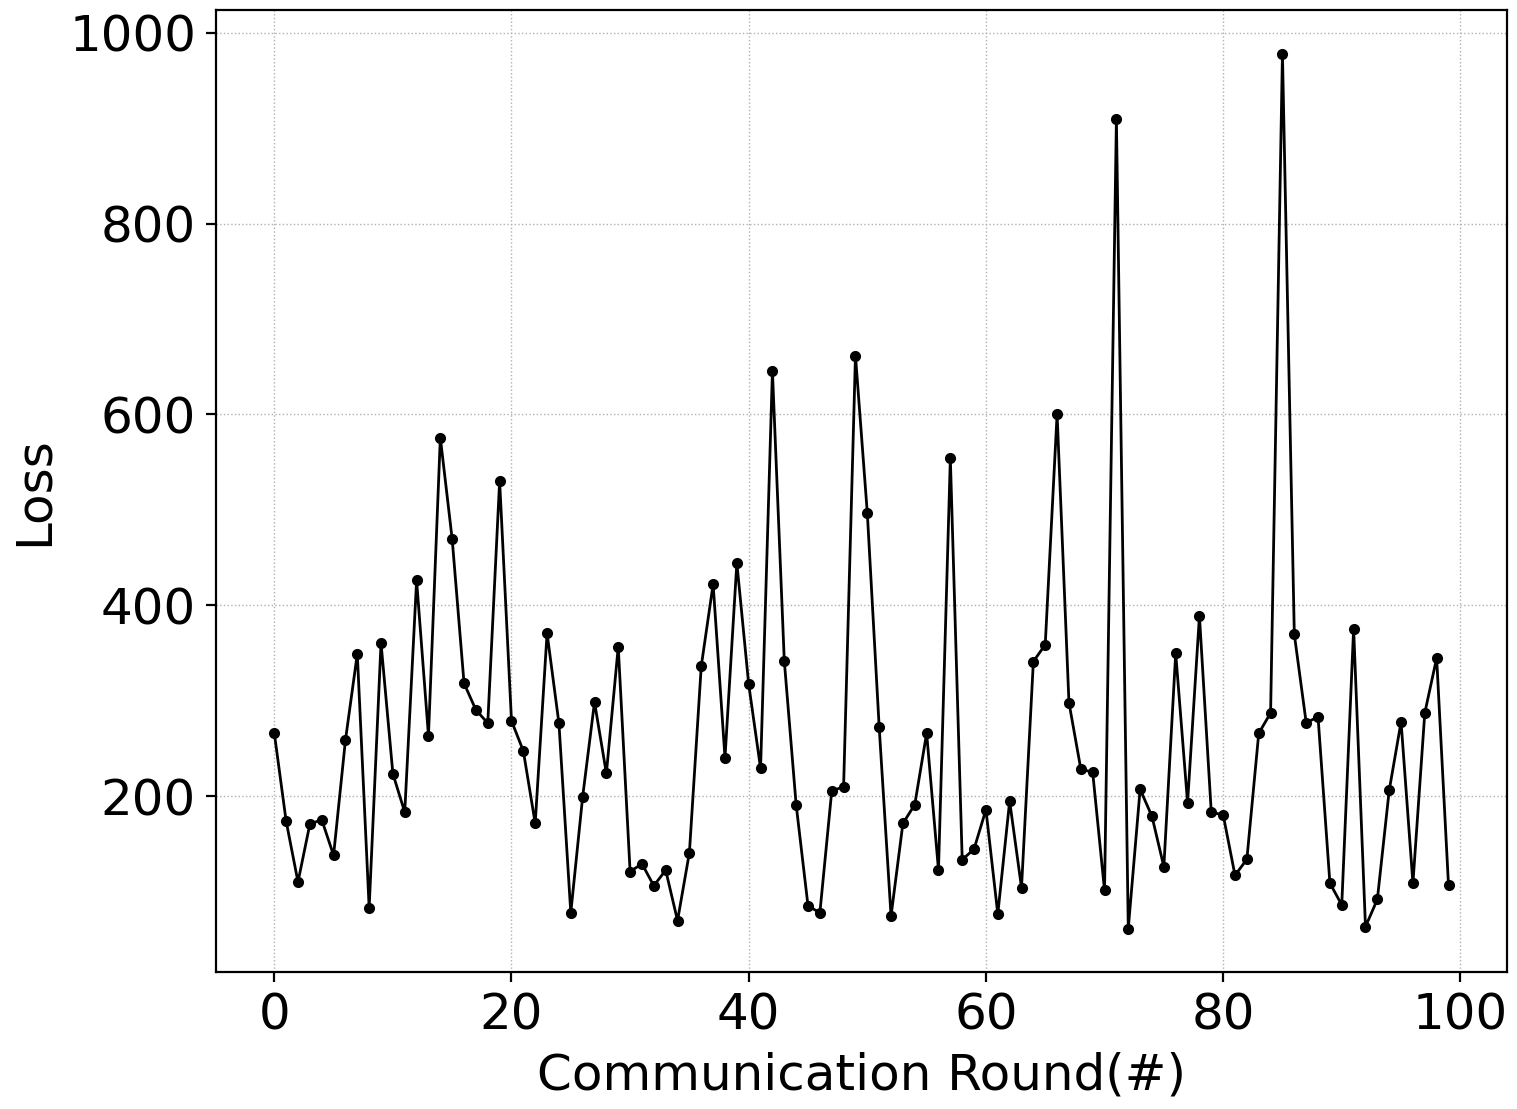

# <center> 7. Final Remarks </center>
The result shows the evolution of loss (specifically, Mean Squared Error, or MSE) over 100 communication rounds in a Federated Learning (FL) setting. The x-axis represents the communication round number, while the y-axis represents the loss value.

Key Observations:
*   High Variability in Loss: The loss fluctuates significantly throughout the training process. In some rounds, the loss spikes up considerably, reaching values above 900, while in other rounds, it drops back down to below 200. This suggests that the model performance is inconsistent across rounds.

*   Lack of Convergence: Ideally, we would expect the loss to steadily decrease over time, showing convergence as the model learns better representations from the distributed data. However, in this case, the loss pattern is erratic and does not show a clear decreasing trend. This might indicate issues such as:
  1.   Non-IID data: The data distribution across
clients may be non-identical and independent, leading to inconsistent updates.
  2.   Heterogeneous clients: Different clients might be providing updates that are drastically different, causing the model to oscillate between different solutions.
  3.   Learning rate tuning: The learning rate might be too high, causing the model to overshoot optimal updates.

*   Initial Loss and Peaks: The initial loss values are in the range of 200 to 300, but shortly after the 20th round, there is a significant spike to around 700–800. Further spikes occur around rounds 40, 60, and 80. These peaks may correspond to certain client updates that push the global model toward suboptimal solutions temporarily.
Dips and Recoveries:

*   Between the major spikes, we observe regions where the loss decreases, suggesting that in certain rounds, the global model is able to incorporate useful information from the clients.
Possible Causes of this Behavior:

*   Client Drift: In Federated Learning, when clients have non-IID data (i.e., the data across clients are not from the same distribution), updates from each client may "pull" the global model in different directions, leading to fluctuations like those seen in the plot.

*   Communication Rounds: Each communication round involves aggregating the model updates from the clients and updating the global model. The loss fluctuations might suggest that the updates from some clients degrade the global model's performance in certain rounds.

*   Aggregation Method: If the aggregation algorithm used (e.g., FedAvg) is not well-suited to handle highly skewed or non-IID data, it can result in the kind of oscillatory behavior seen here.

In summary, the result suggests that the FL model is not converging smoothly and may be experiencing issues with non-IID data, client heterogeneity, or improper learning rate tuning. Adjustments to the training process, such as modifying the learning rate or using more sophisticated aggregation techniques, may be needed to improve the model's performance.


## Thanks for your attention!